WebCam


In [3]:
import cv2
import numpy as np
from mtcnn import MTCNN

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 150:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Initialize MTCNN for face detection
detector = MTCNN()

# Open the webcam (0 is the default camera)
cap = cv2.VideoCapture(0)

while True:
    # Capture each frame from the webcam
    ret, frame = cap.read()

    if not ret:
        break

    # Detect faces in the frame
    faces = detector.detect_faces(frame)

    # Iterate through each face detected by MTCNN
    for i, face in enumerate(faces):
        # Extract the bounding box and landmarks
        x, y, w, h = face['box']
        
        # Crop the face region from the frame
        face_region = frame[y:y+h, x:x+w]
        
        # Convert the face region to HSV
        hsv_face = cv2.cvtColor(face_region, cv2.COLOR_BGR2HSV)

        # Create a binary mask for the skin region in the face
        lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
        upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold
        mask = cv2.inRange(hsv_face, lower_skin, upper_skin)

        # Refine the mask (remove noise)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

        # Classify the skin tone based on histogram analysis
        skin_tone = classify_skin_by_histogram(hsv_face, mask)

        # Draw bounding box around the face and label the skin tone
        cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(frame, f"Skin Tone: {skin_tone}", (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)

    # Display the resulting frame with face and skin tone labels
    cv2.imshow("Webcam Feed with Face and Skin Tone", frame)

    # Exit the webcam feed when 'q' is pressed
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release the webcam and close any OpenCV windows
cap.release()
cv2.destroyAllWindows()


Value Peak: 187
Saturation Peak: 68
Value Peak: 187
Saturation Peak: 68
Value Peak: 180
Saturation Peak: 85
Value Peak: 180
Saturation Peak: 85
Value Peak: 180
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 85
Value Peak: 184
Saturation Peak: 85
Value Peak: 180
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 85
Value Peak: 181
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 85
Value Peak: 179
Saturation Peak: 94
Value Peak: 175
Saturation Peak: 94
Value Peak: 175
Saturation Peak: 91
Value Peak: 176
Saturation Peak: 91
Value Peak: 255
Saturation Peak: 85
Value Peak: 255
Saturation Peak: 90
Value Peak: 179
Saturation Peak: 94
Value Peak: 184
Saturation Peak: 85
Value Peak: 187
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 87
Value Peak: 184
Saturation Peak: 85
Value Peak: 187
Saturation Peak: 85
Value Peak: 187
Saturation Peak: 85
Value Peak: 183
Saturation Peak: 85
Value Peak: 184
Saturation Peak: 85
Value Peak: 183
Saturation P

Image

In [6]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'D:\blueimage.jpg')
# image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\dark.jpg')


hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Show the images
cv2.imshow("Original Image", image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 250
Saturation Peak: 63
Identified Skin Tone: Fair


Value Peak: 250
Saturation Peak: 63
Identified Skin Tone: Fair


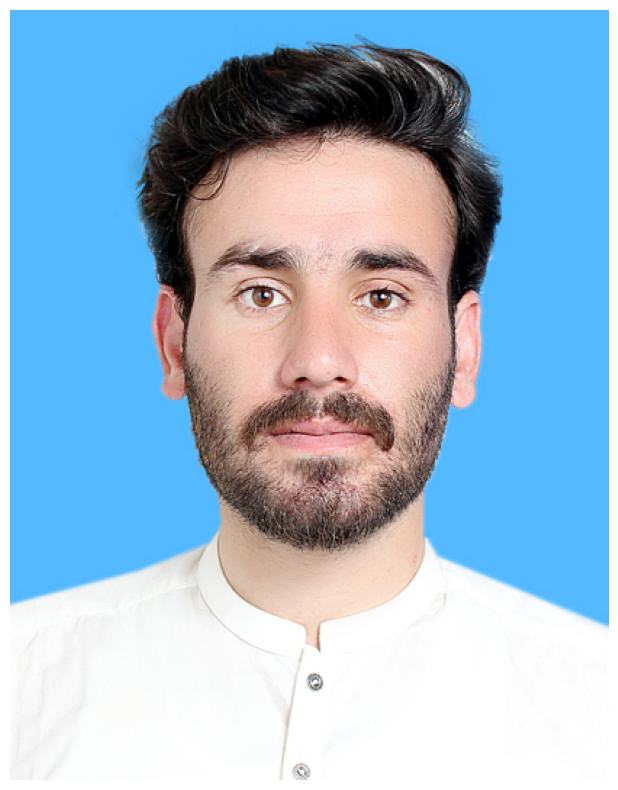

In [17]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'D:\blueimage.jpg')
# image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\dark.jpg')


hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# # Show the images
# cv2.imshow("Original Image", image)
# cv2.imshow("Skin Mask", mask)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

# Display annotated image
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [ ]:
# Display annotated image
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

In [6]:
import cv2

img = cv2.imread(r'D:\blueimage.jpg')
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)


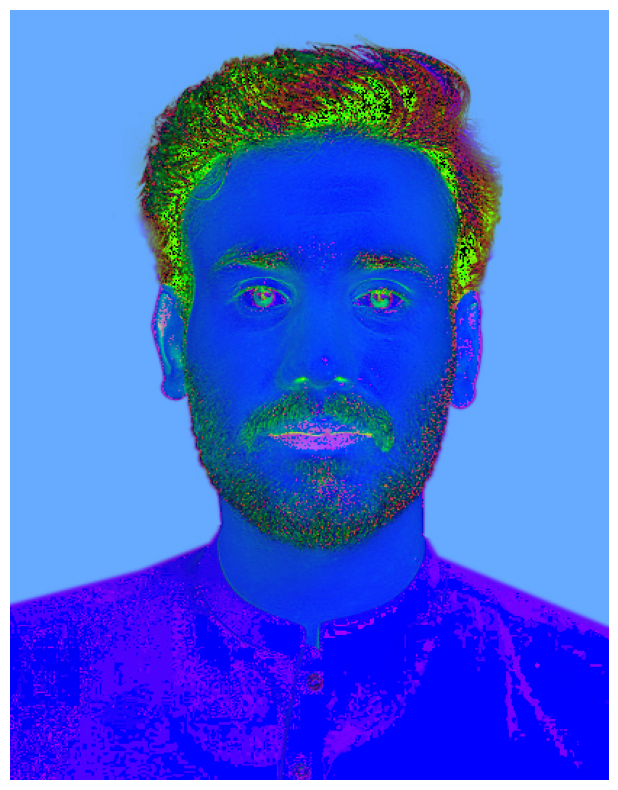

In [11]:
plt.figure(figsize=(10,10))
# plt.imshow(cv2.resize(hsv_image, (100,100)))
plt.imshow(hsv_image)
plt.axis('off')
plt.show()

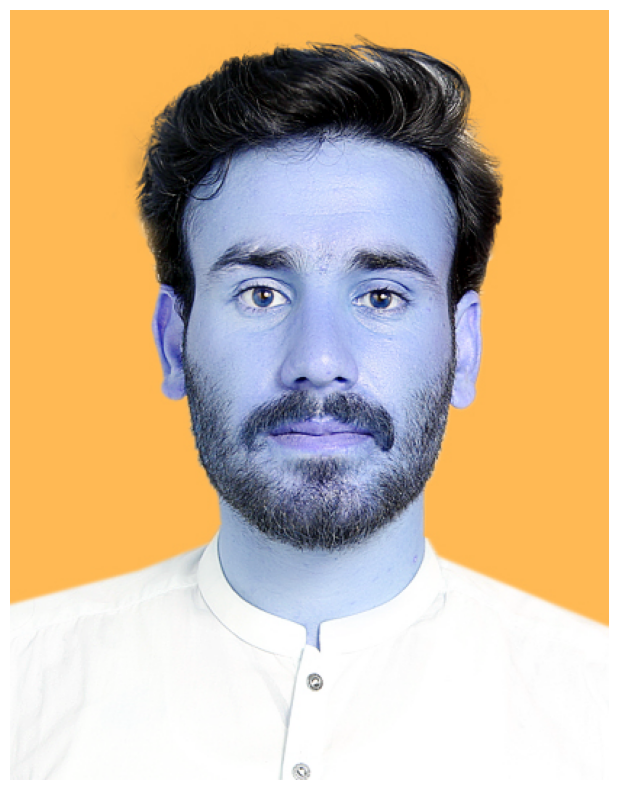

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.imshow(img)
plt.axis('off')
plt.show()

In [58]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread('D:/Creative IT Park/Logo detection/photo.jpg')
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Show the images
cv2.imshow("Original Image", image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 145
Saturation Peak: 70
Identified Skin Tone: Fair


In [59]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\R.jpeg')
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Show the images
cv2.imshow("Original Image", image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 162
Saturation Peak: 141
Identified Skin Tone: Medium


In [4]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\darkest.jpg')

# image = cv2.imread(r'D:\blueimage.jpg')
# image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\dark.jpg')


hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Show the images
cv2.imshow("Original Image", image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 85
Saturation Peak: 48
Identified Skin Tone: Dark


In [7]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'D:\blueimage.jpg')
# image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\dark.jpg')


hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Show the images
cv2.imshow("Original Image", image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 250
Saturation Peak: 63
Identified Skin Tone: Fair


In [16]:
import cv2
import numpy as np

def classify_skin_by_histogram(hsv_image, mask):
    """Classify skin tone using histogram analysis of the HSV image."""
    # Calculate the histogram of the masked image (only skin region)
    hist_hue = cv2.calcHist([hsv_image], [0], mask, [180], [0, 180])  # Hue histogram
    hist_saturation = cv2.calcHist([hsv_image], [1], mask, [256], [0, 256])  # Saturation histogram
    hist_value = cv2.calcHist([hsv_image], [2], mask, [256], [0, 256])  # Value histogram
    
    # Normalize histograms
    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    # Analyze the histograms to classify skin tone
    hue_peak = np.argmax(hist_hue)
    saturation_peak = np.argmax(hist_saturation)
    value_peak = np.argmax(hist_value)
    
    # Print the peaks of value and saturation
    print(f"Value Peak: {value_peak}")
    print(f"Saturation Peak: {saturation_peak}")
    
    # Classifying based on the peak value positions in histograms
    if value_peak > 140:  # Bright skin (Fair)
        if saturation_peak < 80:
            return "Fair"
        else:
            return "Medium"
    elif 100 < value_peak <= 150:  # Moderate brightness (Medium)
        return "Medium"
    else:  # Dark skin (Low value)
        return "Dark"

# Load the image
image = cv2.imread(r'D:\blueimage.jpg')
# image = cv2.imread(r'C:\Users\Muhammad Haroon\Downloads\darkest.jpg')
# image = cv2.imread('D:/Creative IT Park/Logo detection/photo.jpg')



# Check if the image is loaded correctly
if image is None:
    print("Error: Unable to load image. Check the file path.")
    exit()

hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Define skin color range in HSV
lower_skin = np.array([0, 40, 80], dtype=np.uint8)  # Lower threshold
upper_skin = np.array([20, 255, 255], dtype=np.uint8)  # Upper threshold

# Create a binary mask for skin region
mask = cv2.inRange(hsv_image, lower_skin, upper_skin)

# Refine the mask (remove noise)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Classify the skin tone based on histogram analysis
skin_tone = classify_skin_by_histogram(hsv_image, mask)

# Display results
print(f"Identified Skin Tone: {skin_tone}")

# Add the label to the image
output_image = image.copy()
cv2.putText(output_image, f"Skin Tone: {skin_tone}", (50, 50), 
            cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2, cv2.LINE_AA)

# Show the images
cv2.imshow("Original Image with Label", output_image)
cv2.imshow("Skin Mask", mask)
cv2.waitKey(0)
cv2.destroyAllWindows()


Value Peak: 250
Saturation Peak: 63
Identified Skin Tone: Fair
